In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt

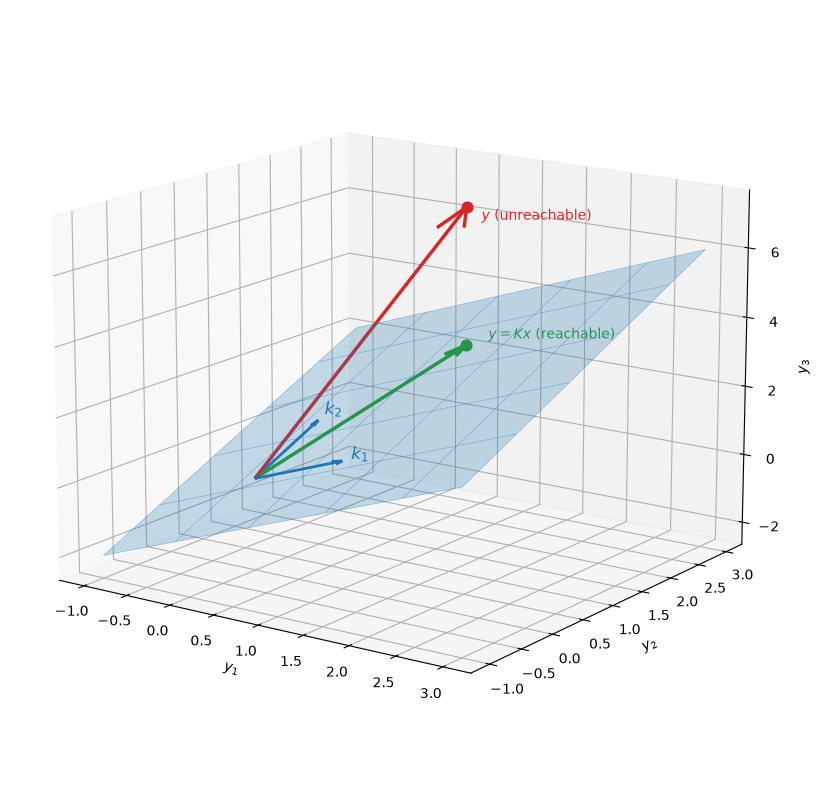

In [19]:
K = np.array([[1, 0],
              [0, 1],
              [1, 1]])

x = np.array([1, 2])

y_reachable = K @ x
y_unreachable = np.array([1, 2, 7])

s, t = np.meshgrid(np.linspace(-1, 3, 20), np.linspace(-1, 3, 20))
P = K @ np.vstack([s.ravel(), t.ravel()])
X, Y, Z = (P[i].reshape(s.shape) for i in range(3))

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection="3d")

ax.plot_surface(X, Y, Z, alpha=0.25, color="tab:blue", edgecolor="none")
ax.plot_wireframe(X, Y, Z, rstride=4, cstride=4, color="tab:blue",
                  linewidth=0.4, alpha=0.5)

o = np.zeros(3)
for col, name in zip(K.T, ["$k_1$", "$k_2$"]):
    ax.quiver(*o, *col, color="tab:blue", linewidth=2, arrow_length_ratio=0.1)
    ax.text(*(col * 1.1), name, color="tab:blue", fontsize=12)

ax.quiver(*o, *y_reachable, color="tab:green", linewidth=2.5,
          arrow_length_ratio=0.08)
ax.scatter(*y_reachable, color="tab:green", s=60)
ax.text(*(y_reachable + 0.15), r"$y = Kx$ (reachable)", color="tab:green")

ax.quiver(*o, *y_unreachable, color="tab:red", linewidth=2.5,
          arrow_length_ratio=0.08)
ax.scatter(*y_unreachable, color="tab:red", s=60)
ax.text(*(y_unreachable + np.array([0.1, 0.1, -0.4])),
        r"$y$ (unreachable)", color="tab:red")

ax.set_xlabel("$y_1$")
ax.set_ylabel("$y_2$")
ax.set_zlabel("$y_3$")
ax.view_init(elev=15, azim=-55)

plt.tight_layout()
plt.savefig(os.getcwd() + "/data/state_v_measurement.png", dpi=150)
plt.show()

array([ True,  True,  True])